# Step 2: Data Visualization
In this notebook we use charts to understand which factors affect loan default.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

## 2. Load cleaned data

In [2]:
df = pd.read_csv('Loan_default_cleaned.csv')
df.head()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


## 3. How many loans defaulted? (Target column)

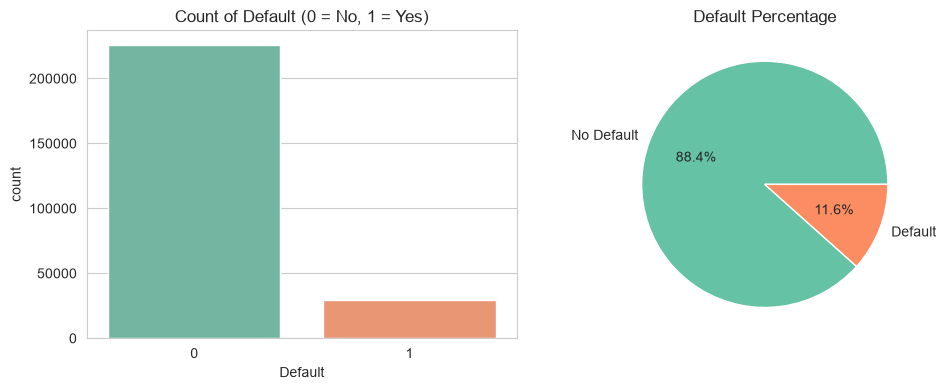

In [3]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.countplot(x='Default', data=df, palette='Set2')
plt.title('Count of Default (0 = No, 1 = Yes)')

plt.subplot(1, 2, 2)
df['Default'].value_counts().plot.pie(autopct='%1.1f%%', labels=['No Default', 'Default'], colors=['#66c2a5', '#fc8d62'])
plt.title('Default Percentage')
plt.ylabel('')

plt.tight_layout()
plt.show()

**Observation:** Only about 11-12% of loans default, so the data is imbalanced.

## 4. Distribution of numeric columns

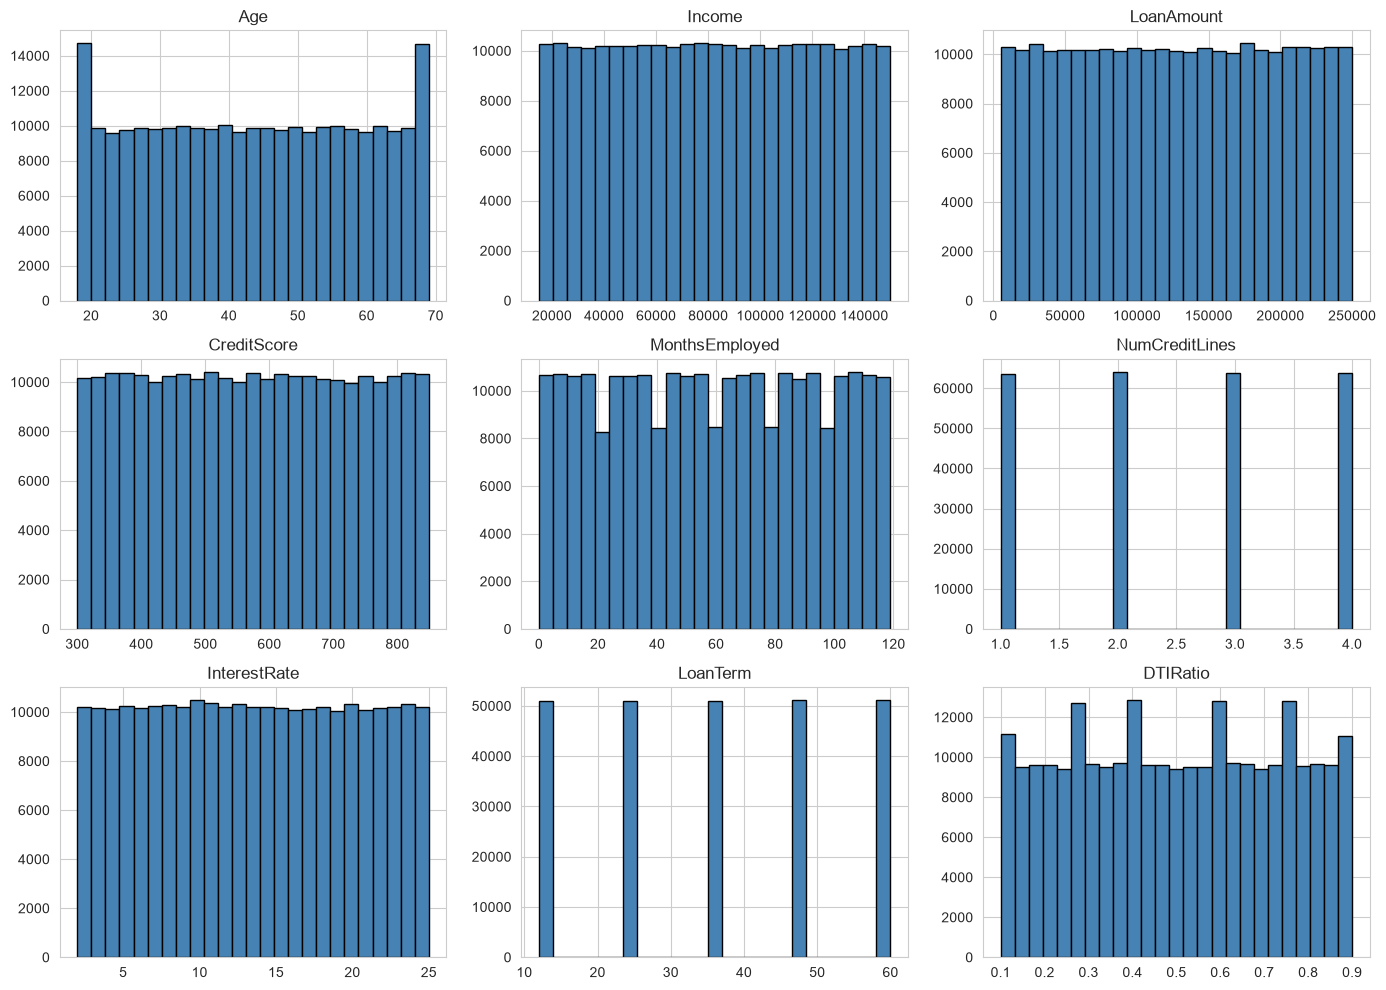

In [4]:
num_cols = ['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
            'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio']

df[num_cols].hist(figsize=(14, 10), bins=25, color='steelblue', edgecolor='black')
plt.tight_layout()
plt.show()

## 5. Age vs Default

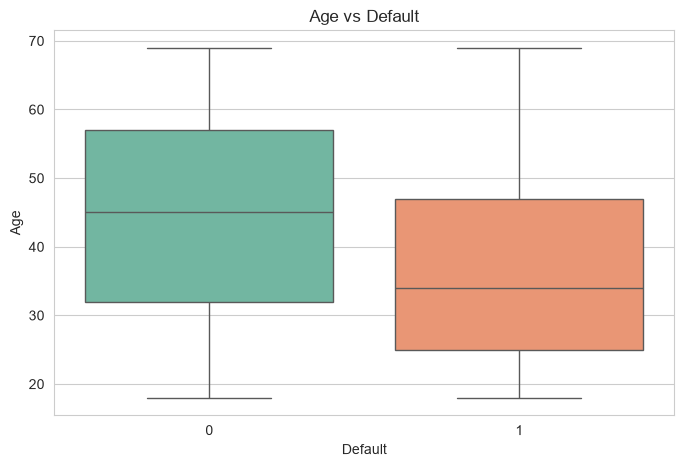

In [5]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Default', y='Age', data=df, palette='Set2')
plt.title('Age vs Default')
plt.show()

**Observation:** Defaulters are usually younger.

## 6. Default rate by Age group

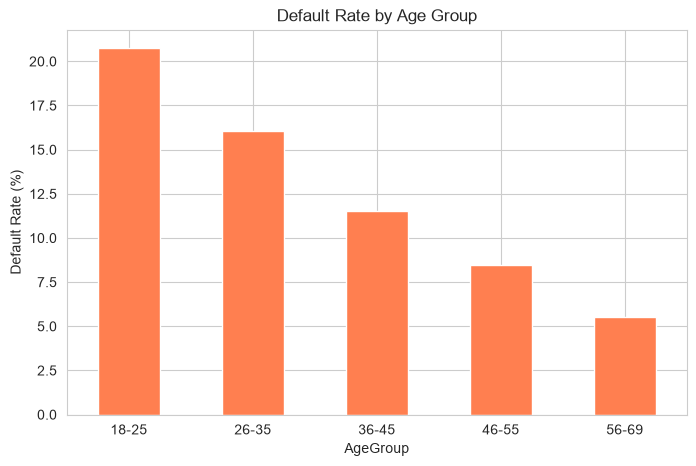

In [6]:
df['AgeGroup'] = pd.cut(df['Age'], bins=[17, 25, 35, 45, 55, 70], labels=['18-25', '26-35', '36-45', '46-55', '56-69'])

age_rate = df.groupby('AgeGroup')['Default'].mean() * 100

plt.figure(figsize=(8, 5))
age_rate.plot(kind='bar', color='coral')
plt.ylabel('Default Rate (%)')
plt.title('Default Rate by Age Group')
plt.xticks(rotation=0)
plt.show()

df = df.drop('AgeGroup', axis=1)   # remove helper column

## 7. Income vs Default

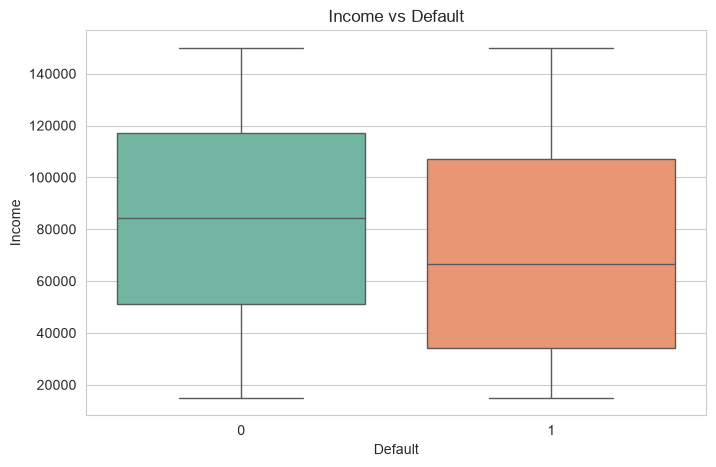

In [7]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Default', y='Income', data=df, palette='Set2')
plt.title('Income vs Default')
plt.show()

## 8. Interest Rate vs Default

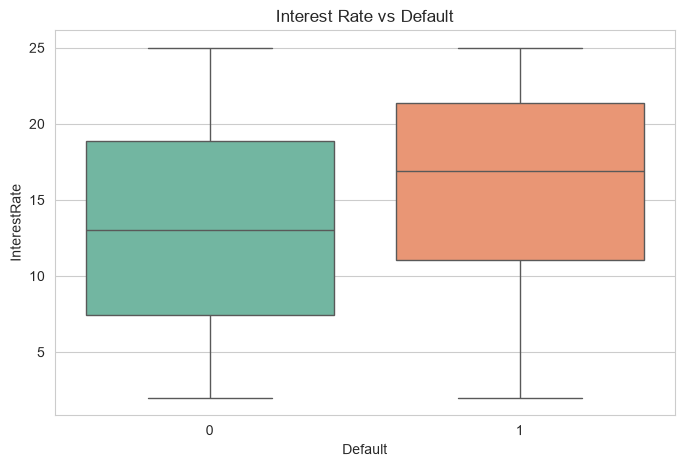

In [8]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Default', y='InterestRate', data=df, palette='Set2')
plt.title('Interest Rate vs Default')
plt.show()

**Observation:** Higher interest rate means higher chance of default.

## 9. Credit Score vs Default

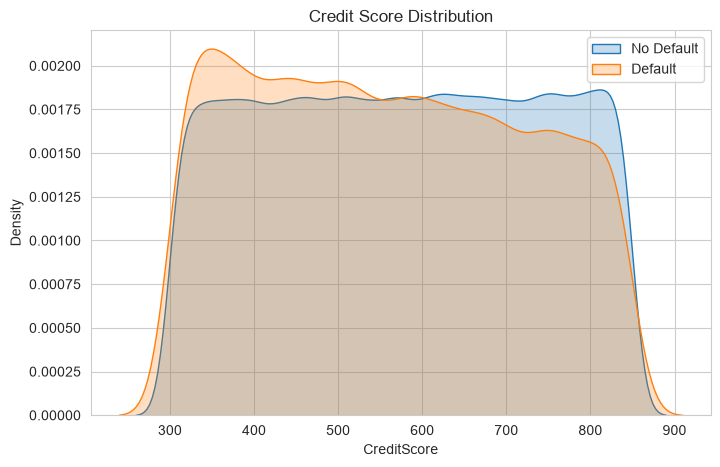

In [9]:
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df[df['Default'] == 0], x='CreditScore', label='No Default', fill=True)
sns.kdeplot(data=df[df['Default'] == 1], x='CreditScore', label='Default', fill=True)
plt.title('Credit Score Distribution')
plt.legend()
plt.show()

## 10. Loan Amount vs Default

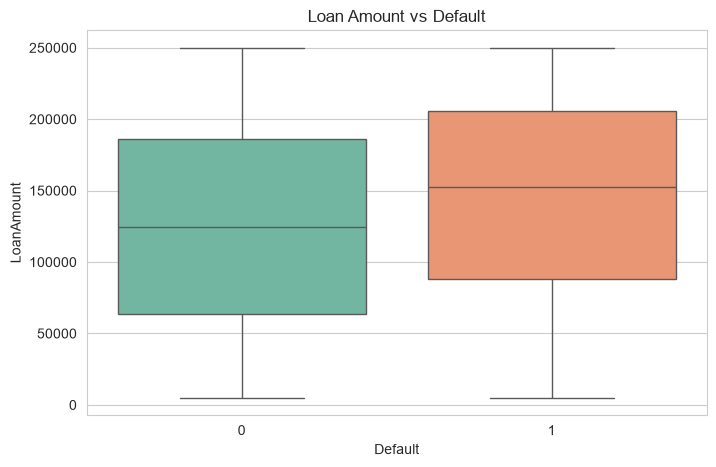

In [10]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Default', y='LoanAmount', data=df, palette='Set2')
plt.title('Loan Amount vs Default')
plt.show()

## 11. Default rate for each category column

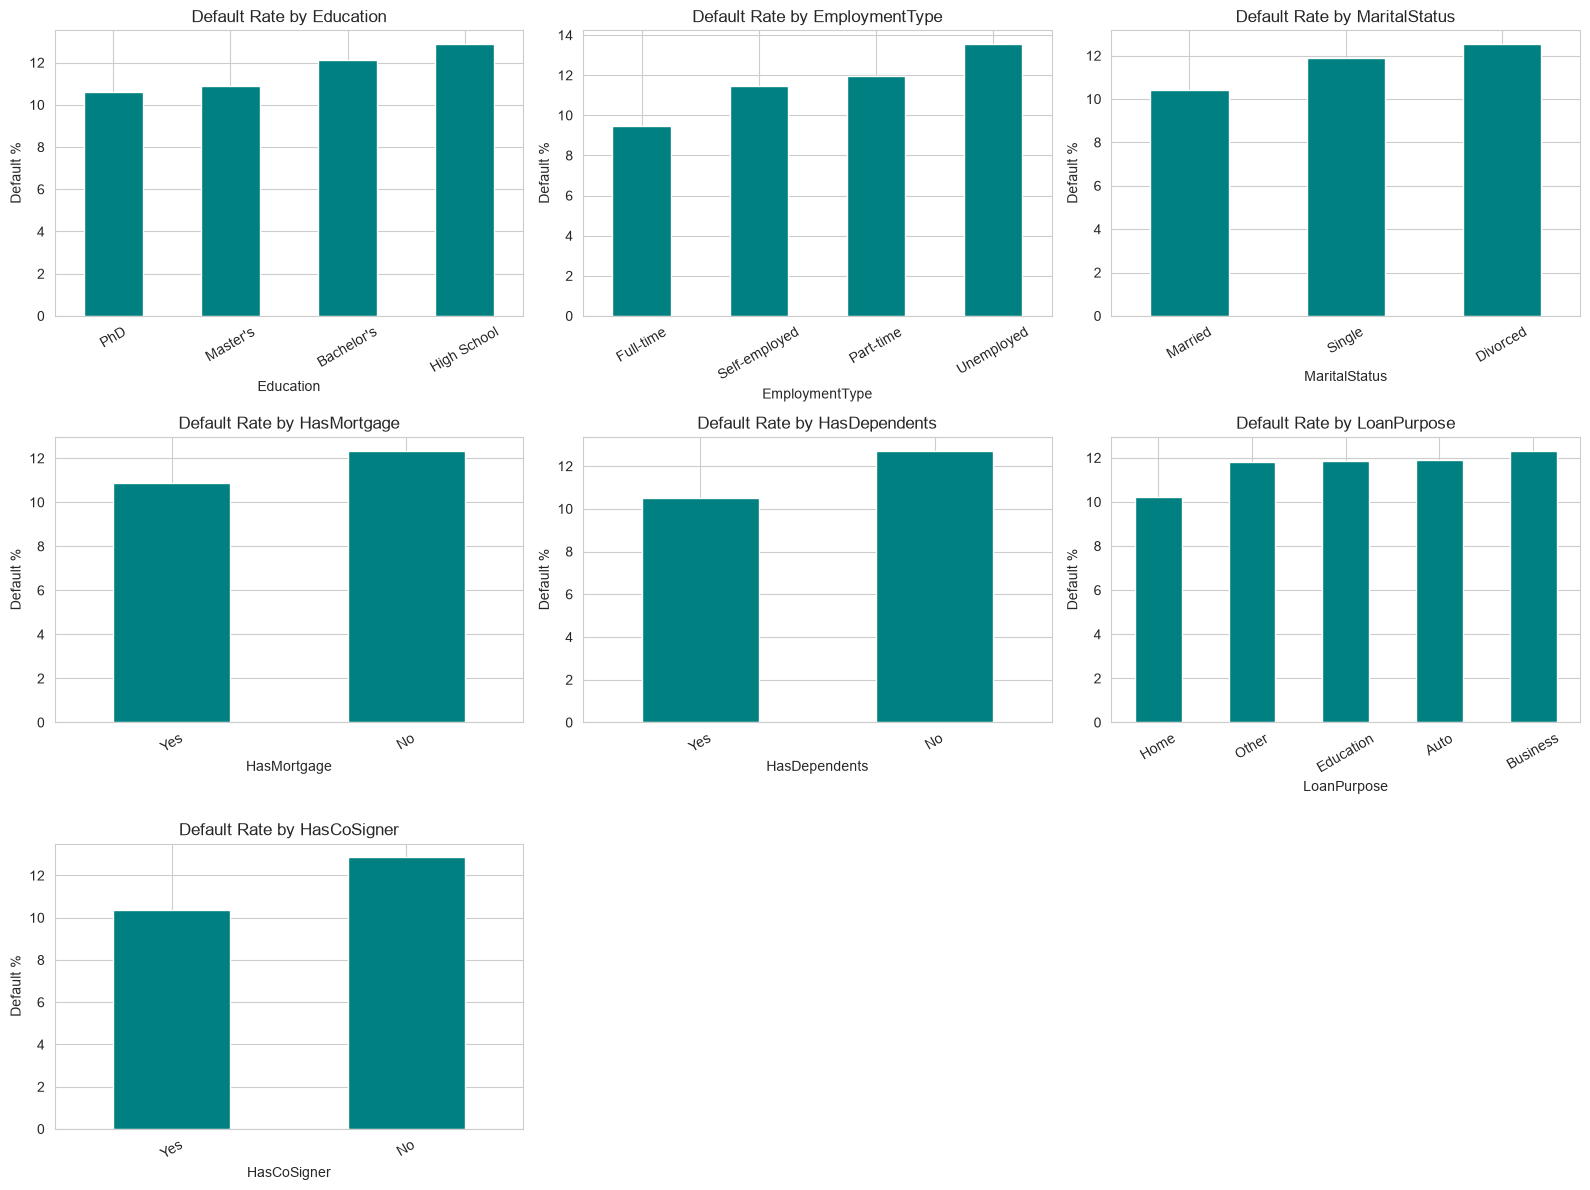

In [11]:
cat_cols = ['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage',
            'HasDependents', 'LoanPurpose', 'HasCoSigner']

plt.figure(figsize=(16, 12))
for i, col in enumerate(cat_cols, 1):
    plt.subplot(3, 3, i)
    rate = df.groupby(col)['Default'].mean() * 100
    rate.sort_values().plot(kind='bar', color='teal')
    plt.title(f'Default Rate by {col}')
    plt.ylabel('Default %')
    plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Observation:** Unemployed people and people without a co-signer default more.

## 12. Correlation heatmap (numeric columns)

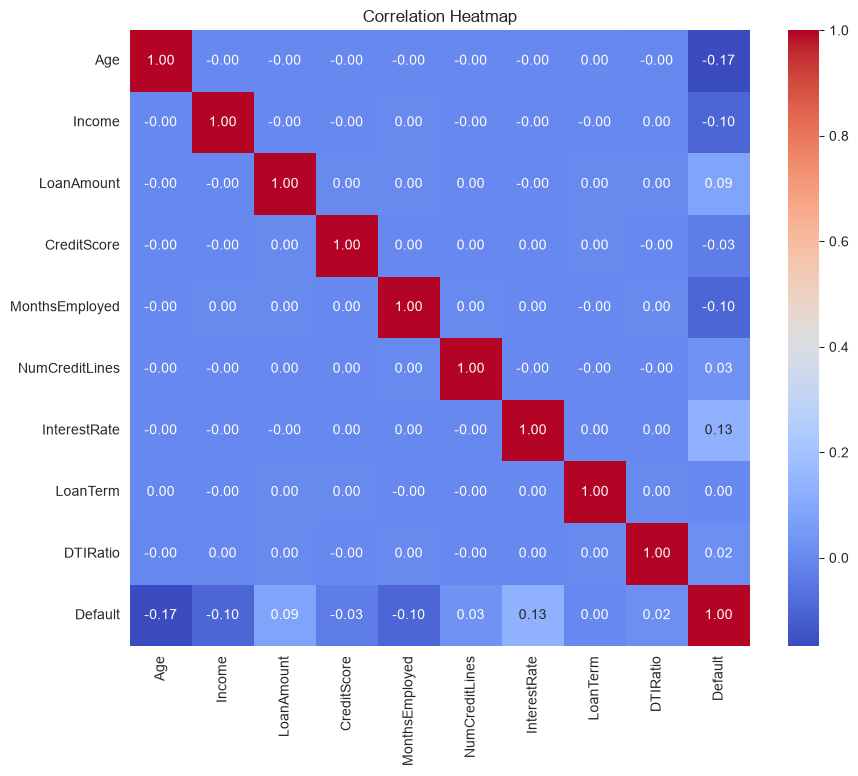

In [12]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols + ['Default']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

## 13. Which numeric column is most related to Default?

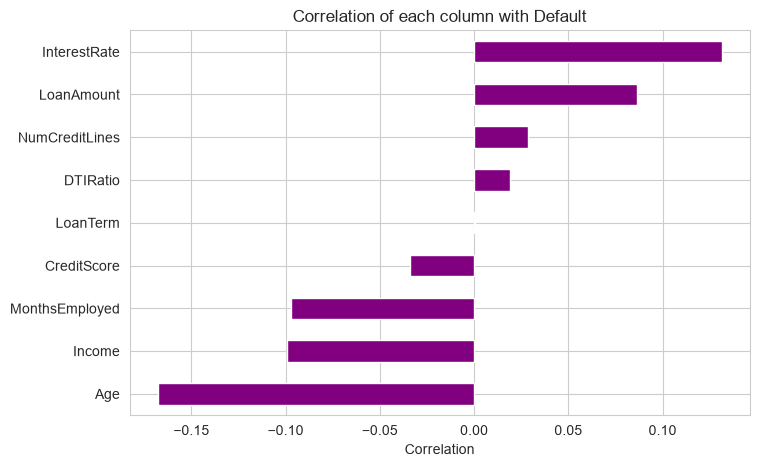

In [13]:
corr = df[num_cols + ['Default']].corr()['Default'].drop('Default').sort_values()

plt.figure(figsize=(8, 5))
corr.plot(kind='barh', color='purple')
plt.title('Correlation of each column with Default')
plt.xlabel('Correlation')
plt.show()

### Summary of findings
- Younger borrowers default more
- Higher interest rate -> more default
- Lower income -> more default
- Unemployed borrowers and those with no co-signer default more

**Next:** open `3_ML_Model.ipynb`